# Урок 11. Почему дальняя перекладина занимает меньше пикселей

[Программа курса](../../README_ru.md)

На прошлом рисунке камера знала, что вершина находится на метр правее и на четыре метра впереди. Этого ещё мало для фотографии. Нужен адрес внутри кадра. Проведём через точку луч, положим поперёк луча маленькую сетку и посмотрим, на какое деление он попадёт.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Один метр на разных расстояниях

Синяя перекладина длиной ровно метр лежит на высоте $y=0.5$ м ниже оптической оси. Слева вид сверху. Лучи от камеры идут к середине и краям перекладины. Справа кадр из 201 столбца и 121 строки. При глубине 4 м и фокусе 80 пикселей перекладина занимает 20 пиксельных интервалов. На глубине 2 м их будет 40. При одинаковом фокусе результат меняет само отношение ширины к глубине.

Зелёная линия слева находится в 0.2 м перед камерой. Когда камера доезжает почти до объекта, перекладина сначала уходит за края кадра, а затем целиком отсекается по глубине. У этих двух исчезновений разные причины, и ниже можно проследить оба по числам.

In [2]:
display(demos.geometry_lab(11, "ru"))

## 2. Где луч проткнёт плоскость

Начало луча — центр камеры $(0,0,0)$. Середина перекладины находится в $P=(1,0.5,4)$ м. По дороге от камеры к точке расстояния по всем трём осям растут в одинаковое число раз. На четверти пути выходит $(1/4,0.5/4,4/4)=(0.25,0.125,1)$ м. Последнее число стало 1. Это пересечение с условной плоскостью, поставленной в метре перед камерой. Удвоенная точка $(2,1,8)$ встретит эту плоскость ровно там же. Один пиксель оставляет целый луч возможных глубин.

В общем виде точка камеры записывается $(x,y,z)$. Чтобы довести последний компонент до 1, все три компонента делятся на $z$. На плоскости остаются $x/z$ и $y/z$. Это отношения метров к метрам, они безразмерны. Для далёкой точки тот же метр поперёк занимает меньшую долю глубины. Деление работает для $z>0$; на нуле у луча нет конечной точки пересечения в общем случае. За камерой, при $z<0$, продолжение прямой уже смотрит в противоположную сторону.

In [3]:
p = np.array([1., .5, 4.])
print("P / z =", p/p[2], "    2P / (2z) =", (2*p)/(2*p[2]))
assert np.allclose(p[:2]/p[2], (2*p)[:2]/(2*p[2]))

P / z = [0.25  0.125 1.   ]     2P / (2z) = [0.25  0.125 1.   ]


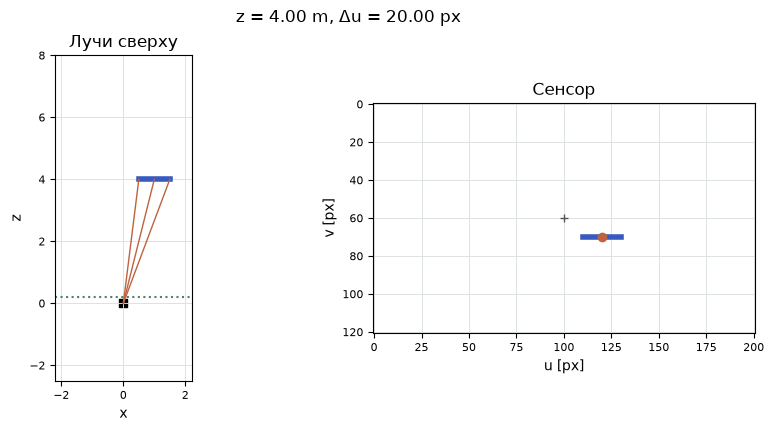

In [4]:
fig = demos.perspective_figure("ru")
plt.show()

## 3. От долей до адреса пикселя

Мы измерили направление. Теперь нужна шкала. Фокус $f_x=80$ пикселей означает, что единице $x/z$ соответствует 80 пиксельных интервалов по горизонтали. В этом опыте $f_y=80$ и по вертикали. Например, $x/z=0.25$ даёт $80\cdot0.25=20$ пикселей вправо от оптической оси. Нижнее смещение $80\cdot0.125=10$ пикселей.

У изображения ширины $W=201$ центры столбцов имеют номера от 0 до 200, поэтому центральный номер $c_x=(W-1)/2=100$. Высота $H=121$ даёт $c_y=60$. Эта пара — главная точка, адрес пересечения оптической оси с кадром. В реальной калибровке её положение оценивается отдельно и может сместиться. Центры пикселей занимают целые координаты, но геометрическое пересечение луча бывает и между ними. Округление до ближайшего адреса меняет задачу, поэтому координаты пока остаются дробными.

$$
\begin{aligned}
u&=c_x+f_x\,x/z=100+80\cdot1/4=120,\\
v&=c_y+f_y\,y/z=60+80\cdot0.5/4=70.
\end{aligned}
$$

Здесь $u$ отсчитывается вправо, $v$ вниз. У левого края перекладины $x=0.5$, откуда $u=110$. У правого $x=1.5$ и $u=130$. Разность концов $130-110=20$ даёт длину в пиксельных интервалах. Если закрасить все целые центры вместе с обоими концами, их окажется 21. Длина линии и число затронутых центров отвечают на разные вопросы.

In [5]:
principal = (100, 60)
for x in [.5, 1, 1.5]:
    print(f"x={x:g} m →", geo.project_point([x,.5,4], 80, principal, near=.2), "px")
np.testing.assert_allclose(geo.project_point(p, (80,100), principal), [120,72.5])

x=0.5 m → [110.  70.] px
x=1 m → [120.  70.] px
x=1.5 m → [130.  70.] px


## 4. Та же запись в виде матрицы

Для двух фокусов и главной точки удобно держать одну матрицу $K$. В верхней строке сначала умножаются $f_x x$ и $c_x z$, затем складываются. Нижняя строка переносит глубину без изменений:

$$
K\begin{bmatrix}x\\y\\z\end{bmatrix}
=\begin{bmatrix}80&0&100\\0&80&60\\0&0&1\end{bmatrix}
\begin{bmatrix}1\\0.5\\4\end{bmatrix}
=\begin{bmatrix}80+400\\40+240\\4\end{bmatrix}
=\begin{bmatrix}480\\280\\4\end{bmatrix}.
$$

Первые две величины пока выражены в пикселях, умноженных на метры. Последнее число — глубина в метрах. Делим на неё и возвращаем прежний адрес $(480/4,280/4)=(120,70)$ px. Если точка задана в мире, перед умножением на $K$ подставляется $B^{\mathsf T}(P-C)$ из прошлого урока.

Камера сдвигается вперёд на 2 м. Мировая точка та же, но теперь её глубина $4-2=2$. Середина окажется в $(140,80)$ px, длина перекладины $80\cdot1/2=40$ px. Тот же результат для **этой** перекладины даёт фокус 160 px со старого места. Для второго объекта на глубине 8 м камера, проехавшая 2 м, изменит размер только в $8/6$ раза, а удвоенный фокус растянет оба объекта вдвое. Так на кадрах различаются приближение камеры и приближение объективом.

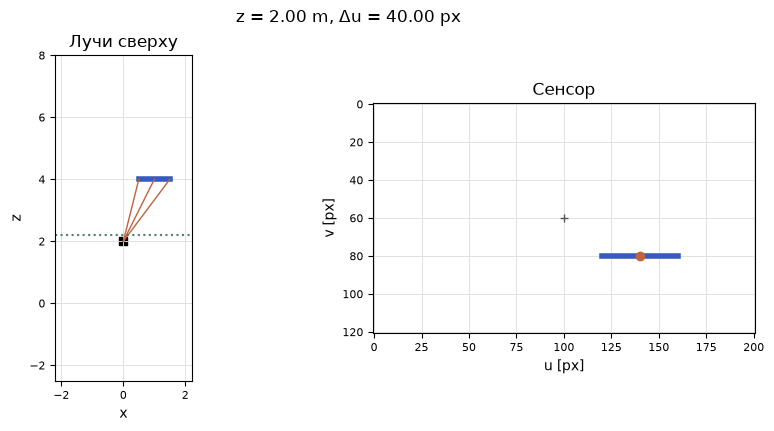

In [6]:
fig = demos.perspective_figure("ru", camera_z=2)
plt.show()

In [7]:
K = np.array([[80, 0, 100], [0, 80, 60], [0, 0, 1]])
h = K @ p
print("Kp =", h, "   (u, v) =", h[:2]/h[2])
for z in [4, 8]:
    print(f"z={z}: move → {80/(z-2):.2f} px; zoom → {160/z:.2f} px")

Kp = [480. 280.   4.]    (u, v) = [120.  70.]
z=4: move → 40.00 px; zoom → 40.00 px
z=8: move → 13.33 px; zoom → 20.00 px


## 5. Два способа потерять точку

Пусть $z=0.5$ м и $x=1$ м. Луч ещё смотрит вперёд, но $u=100+80/0.5=260$ уже за правым краем. При $z=0.2$ срабатывает другое правило: в этой сцене мы сохраняем только глубины **строго больше** 0.2 м. Ближняя плоскость защищает от огромных значений вблизи деления на ноль. Для сегмента с концами по разные стороны плоскости нужна геометрическая отсечка. Наша перекладина параллельна сенсору, поэтому оба конца проходят проверку вместе.

**Опыт.** Пиксель $(120,70)$ и фокус 80 известны, глубина потерялась. Какие две разные точки могли его дать?

<details>
<summary>Разбор</summary>

Из адреса вычитается главная точка $(100,60)$. Получается $(20,10)$. Деление на 80 даёт направление $(0.25,0.125,1)$. Умножение на произвольную положительную глубину восстанавливает точку луча. Глубины 2 и 4 дают $(0.5,0.25,2)$ и $(1,0.5,4)$ м.

</details>

**Проверка на краю.** При $f_x=80$ и $z=4$ какой мировой $x$ попадёт точно в центр последнего столбца?

<details>
<summary>Разбор</summary>

Камера в начале мира, оси совпадают. Последний столбец имеет $u=200$. Смещение от середины $200-100=100$ px. Отношение $x/z=100/80=1.25$. Значит, $x=4\cdot1.25=5$ м. Самый край сенсора проходит ещё на половину пикселя правее центра этого столбца.

</details>

Соглашение о матрице $K$ и переходе из мира в камеру совпадает с записью в [описании модели камеры OpenCV](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html).